# P1-02 — Premium series v2: plots

How much more USDT costs in reais than the official dollar (PTAX), in **basis points** (1 bps = 0.01%).

`premium = USDTBRL / (PTAX × USDTUSD) − 1`, with USDT/BRL averaged over the PTAX window (13–16h UTC = 10–13h Brasília).
Definitions, variants and the column dictionary: `tasks/P1-02-premium-v2.md` → Result.

**Run first:** `python scripts/p1_02_premium.py` (writes the two CSVs read here). Figures are also saved as
`results/figures/P1-02_*.png`. Descriptive only: nothing here tests a cause (that is P2).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results/figures"
FIG.mkdir(parents=True, exist_ok=True)
d = pd.read_csv(ROOT / "data/processed/P1-02_premium_daily.csv", parse_dates=["date_brt"], index_col="date_brt")
h = pd.read_csv(ROOT / "data/processed/P1-02_premium_hourly.csv", parse_dates=["time_utc"], index_col="time_utc")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # categorical slots 1-3, validated (dataviz palette, light mode)
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#b9b8b2", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
GAP = (pd.Timestamp("2022-09-26"), pd.Timestamp("2023-03-11"))  # Binance has no USDC/USDT: BUSD stands in (F-006)
roll = lambda s: s.rolling(21, min_periods=10).median()  # 21 PTAX days ~ one month


def label_end(ax, s, text):
    s = s.dropna()
    ax.annotate(text, (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)


def finish(ax, name, ylabel="premium (bps)"):
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_ylabel(ylabel)
    ax.figure.savefig(FIG / f"P1-02_{name}.png")
    plt.show()

print(f"{len(d)} PTAX days {d.index.min().date()} .. {d.index.max().date()}; {len(h)} hours")

1520 PTAX days 2020-10-13 .. 2026-10-30; 52987 hours


## 1. The main series
Daily premium (gray) and its one-month rolling median (blue).

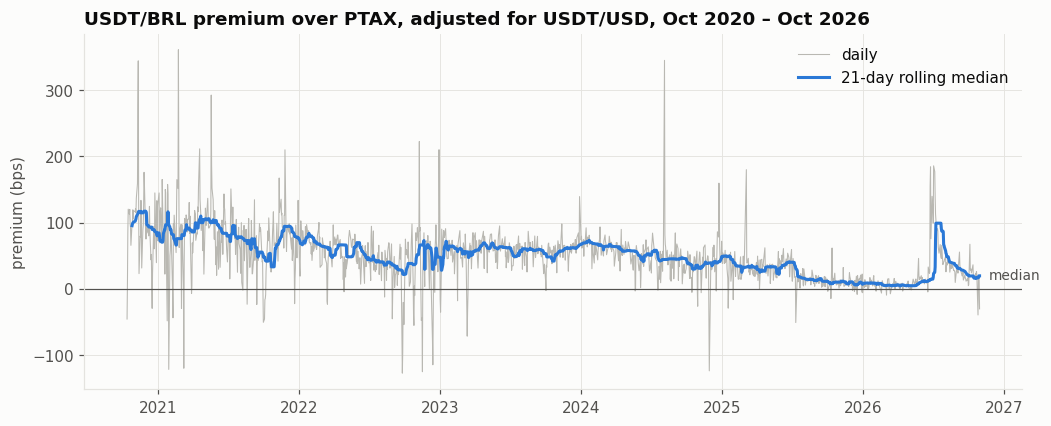

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(d.index, d.premium_bps, color=MUTED, linewidth=0.7, label="daily")
ax.plot(d.index, roll(d.premium_bps), color=BLUE, label="21-day rolling median")
label_end(ax, roll(d.premium_bps), "median")
ax.set_title("USDT/BRL premium over PTAX, adjusted for USDT/USD, Oct 2020 – Oct 2026")
ax.legend(loc="upper right")
finish(ax, "premium_daily")

## 2. Does the USDT/USD adjustment matter?
One-month rolling medians of three versions. Shaded: months where Binance has no USDC, so BUSD stands in (F-006). The Coinbase version starts in May 2021.

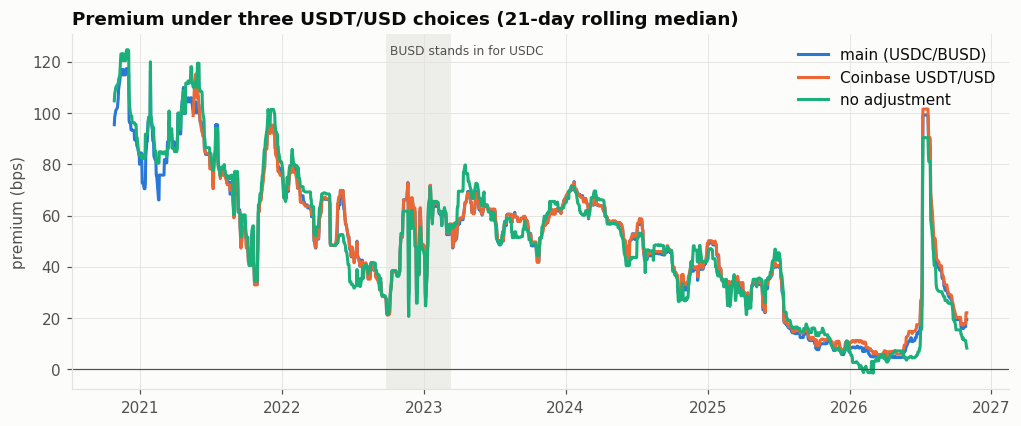

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(*GAP, color=GRID, alpha=0.6, linewidth=0)
ax.text(GAP[0], 0.97, " BUSD stands in for USDC", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=INK2)
for col, color, name in [("premium_bps", BLUE, "main (USDC/BUSD)"), ("premium_cb_bps", ORANGE, "Coinbase USDT/USD"),
                         ("premium_unadj_bps", AQUA, "no adjustment")]:
    ax.plot(d.index, roll(d[col]), color=color, label=name)
ax.set_title("Premium under three USDT/USD choices (21-day rolling median)")
ax.legend(loc="upper right")
finish(ax, "premium_adjustment_variants")

## 3. Does the timing matter?
PTAX-window prices (main) versus the day-close price (24h UTC = 21h Brasília, eight hours after PTAX).

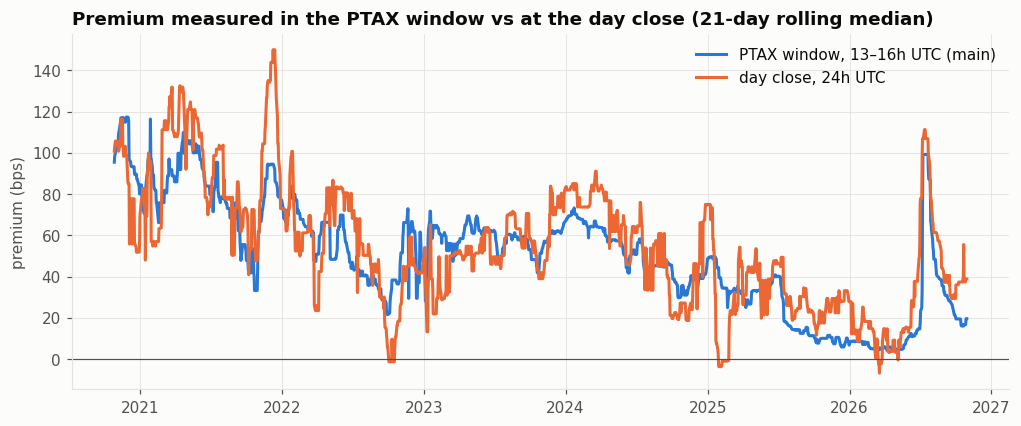

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for col, color, name in [("premium_bps", BLUE, "PTAX window, 13–16h UTC (main)"), ("premium_dayclose_bps", ORANGE, "day close, 24h UTC")]:
    ax.plot(d.index, roll(d[col]), color=color, label=name)
ax.set_title("Premium measured in the PTAX window vs at the day close (21-day rolling median)")
ax.legend(loc="upper right")
finish(ax, "premium_timing_variants")

## 4. USDT's own dollar price, by source
Daily mean inside the PTAX window, in bps away from US$ 1. Negative = USDT below the dollar.

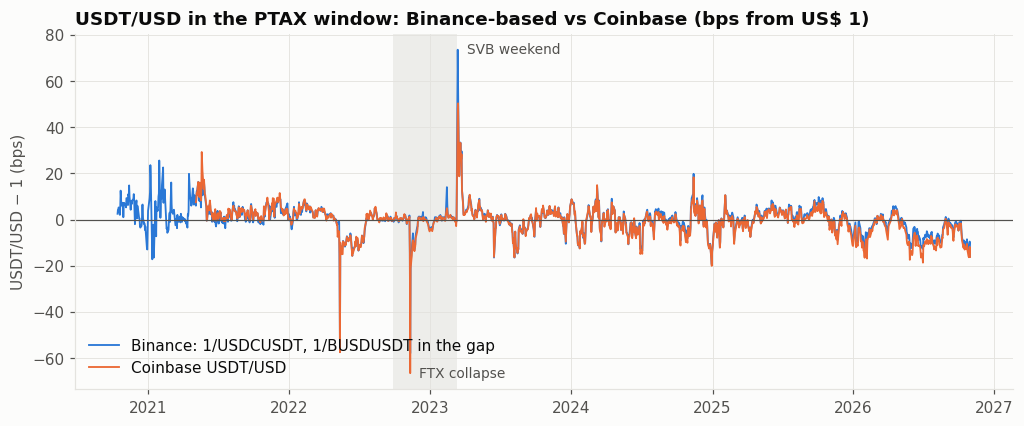

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(*GAP, color=GRID, alpha=0.6, linewidth=0)
ax.plot(d.index, (d.usdtusd_window_usd - 1) * 1e4, color=BLUE, linewidth=1.2, label="Binance: 1/USDCUSDT, 1/BUSDUSDT in the gap")
ax.plot(d.index, (d.usdtusd_cb_window_usd - 1) * 1e4, color=ORANGE, linewidth=1.2, label="Coinbase USDT/USD")
for day, text in [("2022-11-10", "FTX collapse"), ("2023-03-13", "SVB weekend")]:
    v = (d.loc[day, ["usdtusd_window_usd", "usdtusd_cb_window_usd"]].astype(float) - 1) * 1e4
    ax.annotate(text, (pd.Timestamp(day), v.min() if v.mean() < 0 else v.max()), xytext=(6, 0),
                textcoords="offset points", fontsize=9, color=INK2, va="center")
ax.set_title("USDT/USD in the PTAX window: Binance-based vs Coinbase (bps from US$ 1)")
ax.legend(loc="lower left")
finish(ax, "usdtusd_sources", ylabel="USDT/USD − 1 (bps)")

## 5. Zoom: 2025 – Oct 2026
The exploratory jump of F-002 is marked; the event behind it is not yet verified (P1-04).

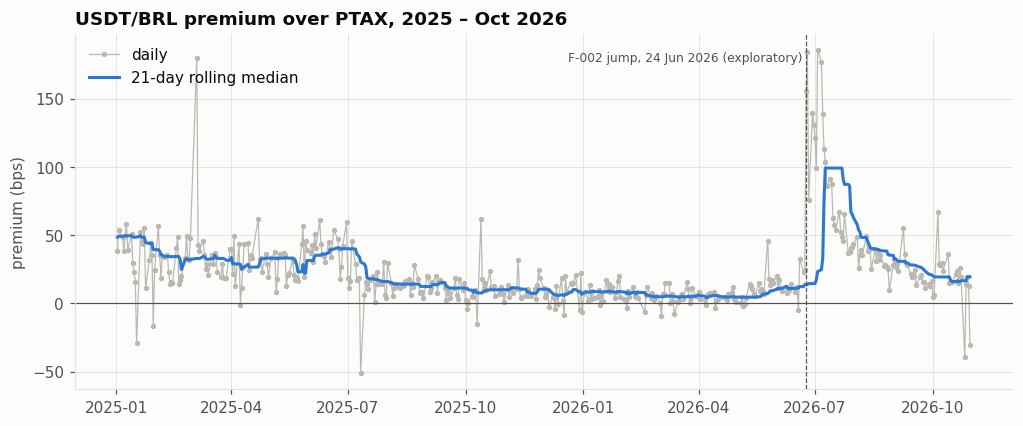

In [6]:
z = d["2025-01-01":]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(z.index, z.premium_bps, color=MUTED, linewidth=0.8, marker="o", markersize=2.5, label="daily")
ax.plot(z.index, roll(d.premium_bps)["2025-01-01":], color=BLUE, label="21-day rolling median")
ax.axvline(pd.Timestamp("2026-06-24"), color=INK2, linewidth=0.8, linestyle="--")
ax.text(pd.Timestamp("2026-06-24"), 0.95, "F-002 jump, 24 Jun 2026 (exploratory) ", transform=ax.get_xaxis_transform(), ha="right", va="top", fontsize=8, color=INK2)
ax.set_title("USDT/BRL premium over PTAX, 2025 – Oct 2026")
ax.legend(loc="upper left")
finish(ax, "premium_daily_2025_2026")

## 6. The hourly series (last eight weeks)
`premium_vs_last_ptax_bps`: every hour's USDT/BRL close against the last PTAX already published. It includes the BRL's own moves since that PTAX, so it is noisier than the daily series and is meant for the weekend and noise work (P2-01, F-003). Weekends shaded.

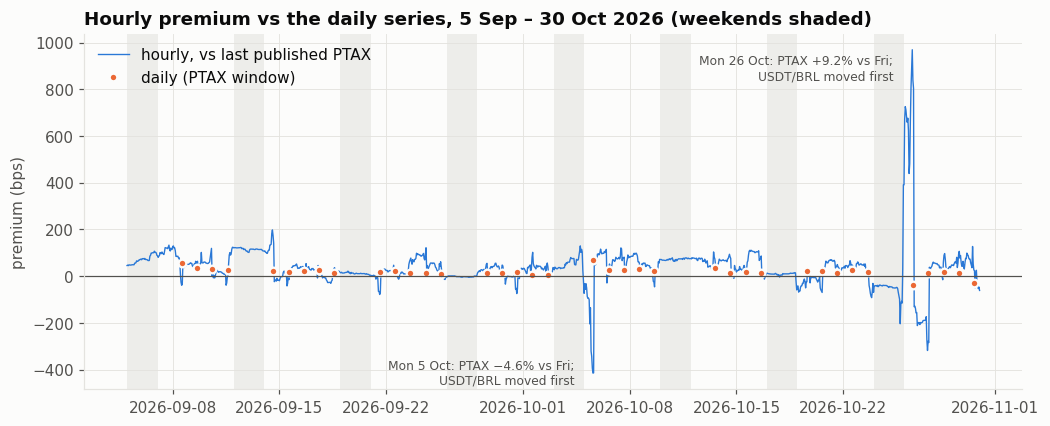

In [7]:
w = h["2026-09-05":]
fig, ax = plt.subplots(figsize=(11, 4.2))
for day in pd.date_range(w.index.min().normalize(), w.index.max(), freq="D"):
    if day.dayofweek == 5:
        ax.axvspan(day, day + pd.Timedelta(days=2), color=GRID, alpha=0.6, linewidth=0)
ax.plot(w.index, w.premium_vs_last_ptax_bps, color=BLUE, linewidth=0.9, label="hourly, vs last published PTAX")
dz = d["2026-09-05":]
ax.plot(dz.index + pd.Timedelta(hours=14, minutes=30), dz.premium_bps, "o", color=ORANGE, markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.5, label="daily (PTAX window)")
for day, text in [("2026-10-05 14:00", "Mon 5 Oct: PTAX −4.6% vs Fri;\nUSDT/BRL moved first"),
                  ("2026-10-26 12:00", "Mon 26 Oct: PTAX +9.2% vs Fri;\nUSDT/BRL moved first")]:
    ax.annotate(text, (pd.Timestamp(day), w.premium_vs_last_ptax_bps[day]), xytext=(-12, 0), textcoords="offset points",
                ha="right", va="center", fontsize=8, color=INK2)
ax.set_title("Hourly premium vs the daily series, 5 Sep – 30 Oct 2026 (weekends shaded)")
ax.legend(loc="upper left")
finish(ax, "premium_hourly_recent")

## 7. Yearly means (bps), all versions
`probe_unadj` is the day-0 probe (F-001, data to 30 Sep 2026); `premium_unadj_bps` reproduces it exactly when cut at the same date.

In [8]:
cols = ["premium_bps", "premium_cb_bps", "premium_unadj_bps", "premium_dayclose_bps"]
y = d.groupby(d.index.year)
t = pd.concat([y.size().rename("days"), y[cols].mean(), y.premium_bps.median().rename("premium_median_bps")], axis=1)
t["probe_unadj"] = pd.Series({2020: 101.2, 2021: 82.3, 2022: 45.2, 2023: 57.6, 2024: 48.6, 2025: 23.3, 2026: 20.4})
t.index.name = "year"
t.round(1)

,days,premium_bps,premium_cb_bps,premium_unadj_bps,premium_dayclose_bps,premium_median_bps,probe_unadj
year,,,,,,,
2020,56,97.2,NaN,101.2,91.6,96.0,101.2
2021,251,78.6,74.0,82.3,90.5,83.2,82.3
2022,251,46.9,47.0,45.2,50.3,53.2,45.2
2023,249,56.1,56.5,57.6,53.9,59.6,57.6
2024,253,49.3,50.0,48.6,57.0,51.1,48.6
2025,252,22.2,23.1,23.3,28.6,18.2,23.3
2026,208,24.0,25.9,19.2,34.9,13.1,20.4


## Observations (descriptive, 31 Oct 2026; nothing here is a causal claim)
- **Level.** The one-month median falls from ~100 bps (late 2020) to 40–70 bps (2022–2024) and ~10 bps (Aug 2025 – mid-Jun 2026),
  jumps to ~100 bps in July 2026, and is back near 20 bps by October 2026. The 2026 jump (F-002) holds in v2: 30-day mean
  15 → 104 bps around 23 Jun; but it largely **reverts** within about three months.
- **A second step** is visible around Jul 2025 (~35–40 → ~15 bps): a candidate for the blind break test (P2-02).
- **USDT/USD adjustment** moves yearly means by at most ~5 bps (2026: USDT sat 5–15 bps below US$ 1). It matters on single days:
  SVB (13 Mar 2023, USDT above the dollar) and FTX (10 Nov 2022, USDT below it). Binance-based and Coinbase agree (F-006).
- **Timing matters more than the adjustment:** the day-close version is noisier and in 2025–26 sits ~5–20 bps above the PTAX-window one.
- **Hourly series:** on the weekends of 4 and 25 Oct 2026 USDT/BRL moved 4–9% before the official market reopened, and Monday's PTAX
  confirmed the moves. Relevant to the weekend question (F-003); what happened on those Sundays is `[verify]`.